# How a data signal loses value as more funds buy it
**Group [N], Session 8 vibe-coding part.** A toy market: one vendor (think Orbital Insight) sells the same parking-lot signal to *k* hedge funds.

**Question:** how many clients should the vendor sell to, what price does that imply, and can this market ever support a company that raised ~$130M?

Every input below is tagged **[REAL]** (from a source) or **[ASSUMPTION]** (our choice, which we vary).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- REAL numbers ----------------
EDGE_EXCLUSIVE = 0.0476   # [REAL] buy-minus-sell return, 3 days around earnings (Katona et al. 2025, Table 3, factor-adjusted)
EVENTS_PER_YEAR = 4       # [REAL] US retailers report quarterly
OI_FUNDING = 130e6        # [REAL] venture capital raised by Orbital Insight (Poulson 2023)
OI_REVENUE_2023 = 9.5e6   # [REAL] expected 2023 revenue, all customers (Poulson 2023)
PRICE_BAND = (100e3, 900e3)  # [REAL] 'hundreds of thousands of dollars per year' (Katona et al. 2025, p. 556)
PRICE_OBS = 500e3          # [ASSUMPTION] midpoint of that band, used for the calibration check

# ---------------- ASSUMPTIONS ----------------
CAPITAL = 50e6            # [ASSUMPTION] $ a fund can put on the long-short trade each quarter
PROCESSING = 250e3        # [ASSUMPTION] each fund's own yearly cost to process/integrate the data
K_MAX = 100
k = np.arange(1, K_MAX + 1)

# How fast each fund's edge shrinks as k funds trade the same signal.
# Each function returns edge(k) / edge(1).  [ASSUMPTION] -- we try four.
DECAY = {
    "Slow (1 / (1 + 0.1(k-1)))":  lambda k: 1 / (1 + 0.1 * (k - 1)),
    "Fixed pie (1 / k)":          lambda k: 1 / k,
    "Competition (4 / (k+1)²)":   lambda k: 4 / (k + 1) ** 2,
    "Fast (exp(-0.3(k-1)))":      lambda k: np.exp(-0.3 * (k - 1)),
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed order, colour-blind checked


### Why these four curves
- **Fixed pie (1/k):** the mispricing is a fixed amount of money; k funds split it equally.
- **Competition (4/(k+1)²):** funds race to trade first and push the price before the announcement (Cournot competition with linear price impact). Together they earn *less* than one exclusive fund would. Normalised so k=1 gives the full 4.76%.
- **Slow / Fast:** bracket the plausible range. Nobody knows the true speed, so we show it as a range rather than a single answer.

In [2]:
def fund_profit(k, decay, capital=CAPITAL):
    """Gross yearly trading profit of ONE fund when k funds hold the signal."""
    return EDGE_EXCLUSIVE * decay(k) * capital * EVENTS_PER_YEAR

def price(k, decay, capital=CAPITAL, processing=PROCESSING):
    """Most a fund would pay per year = its profit minus its own processing cost.
    Upper bound: assumes the vendor captures ALL of the fund's surplus."""
    return np.maximum(fund_profit(k, decay, capital) - processing, 0)

def vendor_revenue(k, decay, **kw):
    return k * price(k, decay, **kw)

# ---- sanity checks (the AI-written code could be wrong: test it) ----
assert np.isclose(fund_profit(1, DECAY["Fixed pie (1 / k)"]), 0.0476 * 50e6 * 4)
assert np.isclose(DECAY["Competition (4 / (k+1)²)"](1), 1.0)
# fixed pie: total trading profit across all funds must stay constant
tot = [kk * fund_profit(kk, DECAY["Fixed pie (1 / k)"]) for kk in (1, 5, 20)]
assert np.allclose(tot, tot[0])
print(f"One exclusive fund earns ${fund_profit(1, lambda k: 1)/1e6:.2f}M a year from the signal")


One exclusive fund earns $9.52M a year from the signal


In [3]:
fmt = lambda x: f"${x/1e6:.1f}M" if x >= 1e6 else f"${x/1e3:.0f}k"
rows = []
print(f"{'Decay assumption':30s} {'best k':>7s} {'price/client':>13s} {'vendor revenue':>15s}")
for name, d in DECAY.items():
    r = vendor_revenue(k, d)
    i = int(np.argmax(r))
    rows.append((name, k[i], price(k[i], d), r[i]))
    print(f"{name:30s} {k[i]:7d} {fmt(price(k[i], d)):>13s} {fmt(r[i]):>15s}")
print(f"\nOrbital Insight actual 2023 revenue (all products): {fmt(OI_REVENUE_2023)}; funding raised: {fmt(OI_FUNDING)}")


Decay assumption                best k  price/client  vendor revenue
Slow (1 / (1 + 0.1(k-1)))           50         $1.4M          $68.2M
Fixed pie (1 / k)                    1         $9.3M           $9.3M
Competition (4 / (k+1)²)             1         $9.3M           $9.3M
Fast (exp(-0.3(k-1)))                3         $5.0M          $14.9M

Orbital Insight actual 2023 revenue (all products): $9.5M; funding raised: $130.0M


### Calibration check: which curve fits the real price?
We know roughly what funds paid (≈ $500k a year). For each curve, find the number of clients at which the price falls to that level, and the vendor revenue that implies. Compare it with Orbital Insight's real revenue.

In [4]:
def k_at_price(d, p_obs=PRICE_OBS, **kw):
    p = price(k, d, **kw)
    hit = np.where(p <= p_obs)[0]
    return k[hit[0]] if len(hit) else None

print(f"{'Decay assumption':30s} {'k at $500k':>10s} {'implied revenue':>16s}")
for name, d in DECAY.items():
    kk = k_at_price(d)
    print(f"{name:30s} {str(kk) if kk else '>'+str(K_MAX):>10s} {fmt(vendor_revenue(kk, d)) if kk else 'n/a':>16s}")


Decay assumption               k at $500k  implied revenue
Slow (1 / (1 + 0.1(k-1)))            >100              n/a
Fixed pie (1 / k)                      13            $6.3M
Competition (4 / (k+1)²)                7            $2.4M
Fast (exp(-0.3(k-1)))                  10            $3.9M


The three fast-shrinking curves reach the observed price with about 7–13 clients and imply **$2–6M** of revenue. That is the same order as Orbital Insight's real $9.5M (which also included other products). The slow curve is still above that price with 100 clients, which would mean $60M+ of revenue. **The real price and the real revenue fit the curves where the edge shrinks fast.**

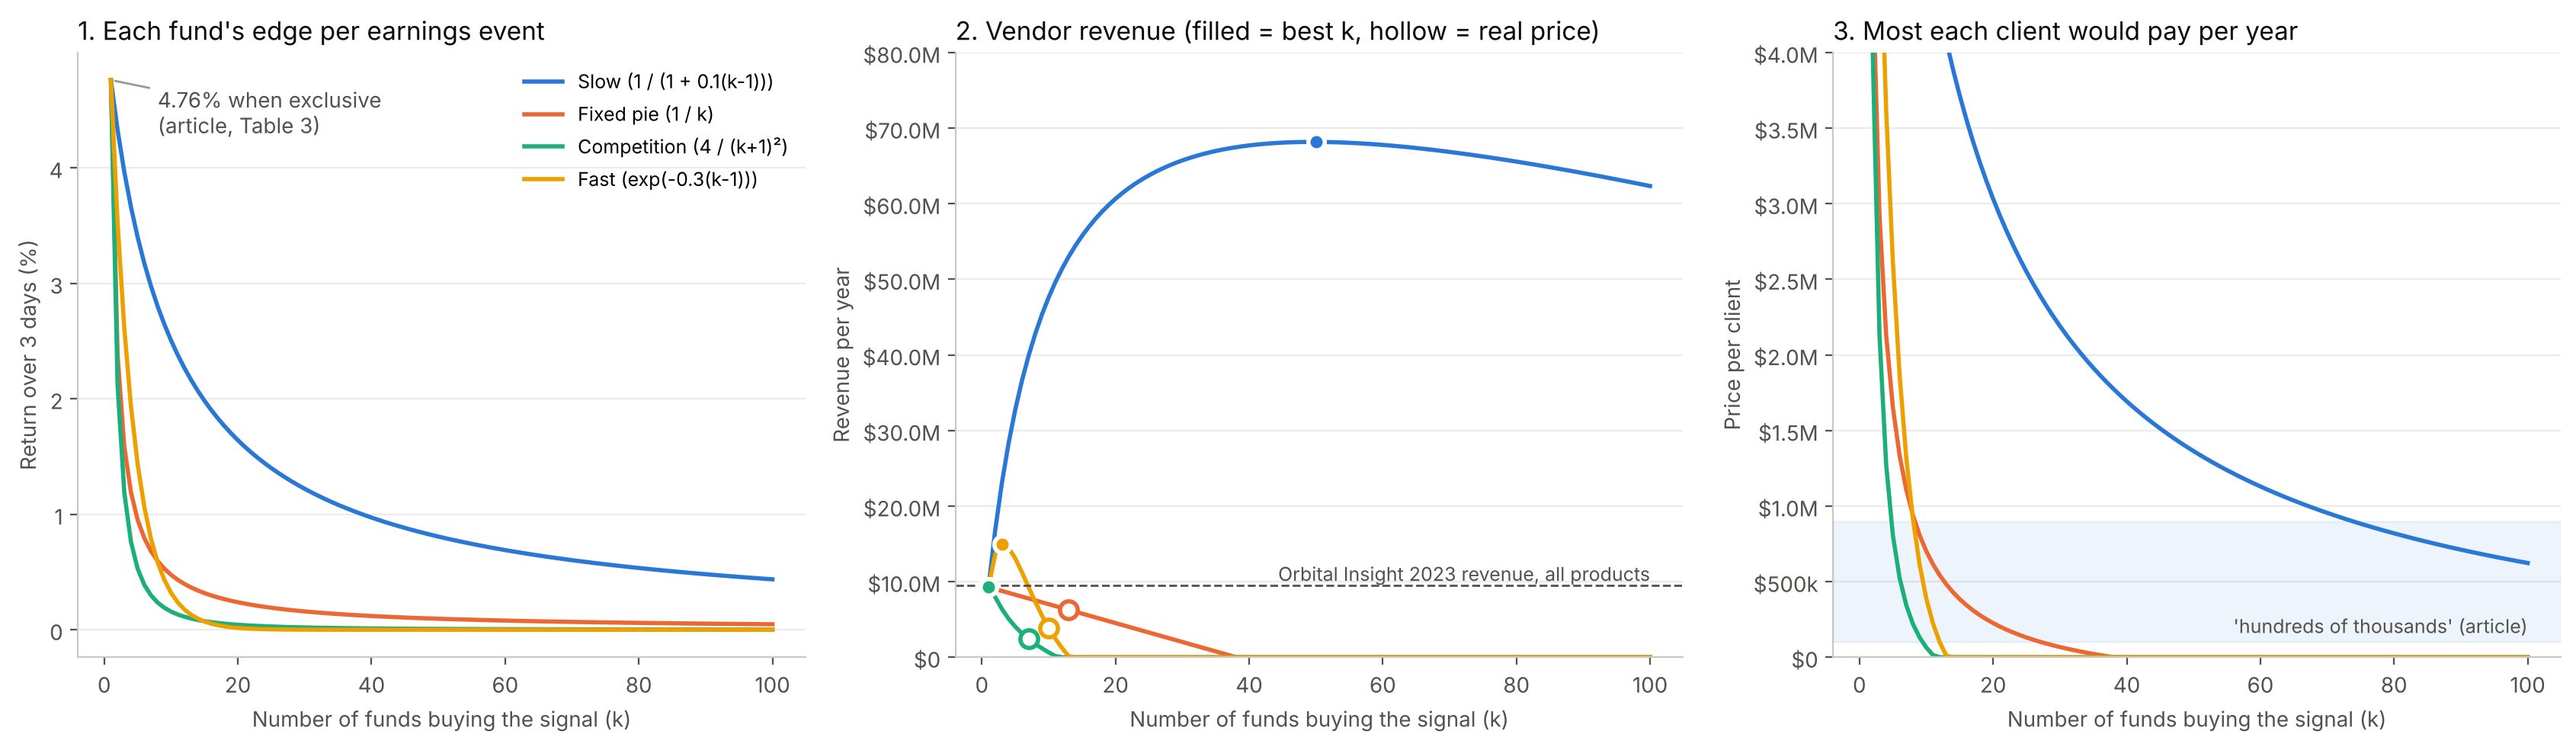

In [5]:
def style(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=12, color="#0b0b0b")
    ax.set_xlabel("Number of funds buying the signal (k)", color="#52514e")
    ax.set_ylabel(ylabel, color="#52514e")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color("#c9c8c2")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="y", color="#ecebe7", lw=0.8); ax.set_axisbelow(True)

money = plt.FuncFormatter(lambda x, _: fmt(x) if x > 0 else "$0")

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for (name, d), c in zip(DECAY.items(), COLORS):
    ax[0].plot(k, 100 * EDGE_EXCLUSIVE * d(k), color=c, lw=2, label=name)
    r = vendor_revenue(k, d); i = int(np.argmax(r))
    ax[1].plot(k, r, color=c, lw=2, label=name)
    ax[1].scatter(k[i], r[i], color=c, s=60, zorder=3, edgecolor="white", lw=2)
    kc = k_at_price(d)
    if kc: ax[1].scatter(kc, vendor_revenue(kc, d), s=70, zorder=3, facecolor="white", edgecolor=c, lw=2)
    ax[2].plot(k, price(k, d), color=c, lw=2, label=name)

style(ax[0], "1. Each fund's edge per earnings event", "Return over 3 days (%)")
ax[0].annotate("4.76% when exclusive\n(article, Table 3)", (1, 4.76), (8, 4.3), color="#52514e",
               arrowprops=dict(arrowstyle="-", color="#9a998f"))

style(ax[1], "2. Vendor revenue (filled = best k, hollow = real price)", "Revenue per year")
ax[1].yaxis.set_major_formatter(money); ax[1].set_ylim(0, 8e7)
ax[1].axhline(OI_REVENUE_2023, color="#52514e", ls="--", lw=1)
ax[1].text(K_MAX, OI_REVENUE_2023, "Orbital Insight 2023 revenue, all products", ha="right", va="bottom", color="#52514e", fontsize=9)

style(ax[2], "3. Most each client would pay per year", "Price per client")
ax[2].yaxis.set_major_formatter(money)
ax[2].axhspan(*PRICE_BAND, color="#2a78d6", alpha=0.08)
ax[2].text(K_MAX, PRICE_BAND[0] + 30e3, "'hundreds of thousands' (article)", ha="right", va="bottom", color="#52514e", fontsize=9)
ax[2].set_ylim(0, 4e6)
ax[0].legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig("fig1_signal_decay.png", dpi=180); plt.show()


### Reading figure 3
The observed price ("hundreds of thousands" a year) sits in the shaded band. An exclusive client would pay up to ~$9M a year. The price only falls to the reported level once the signal is shared, by about 7–13 funds under the fast curves. So the price in the article is itself a sign that the edge had already spread. It was not the price of an exclusive product.

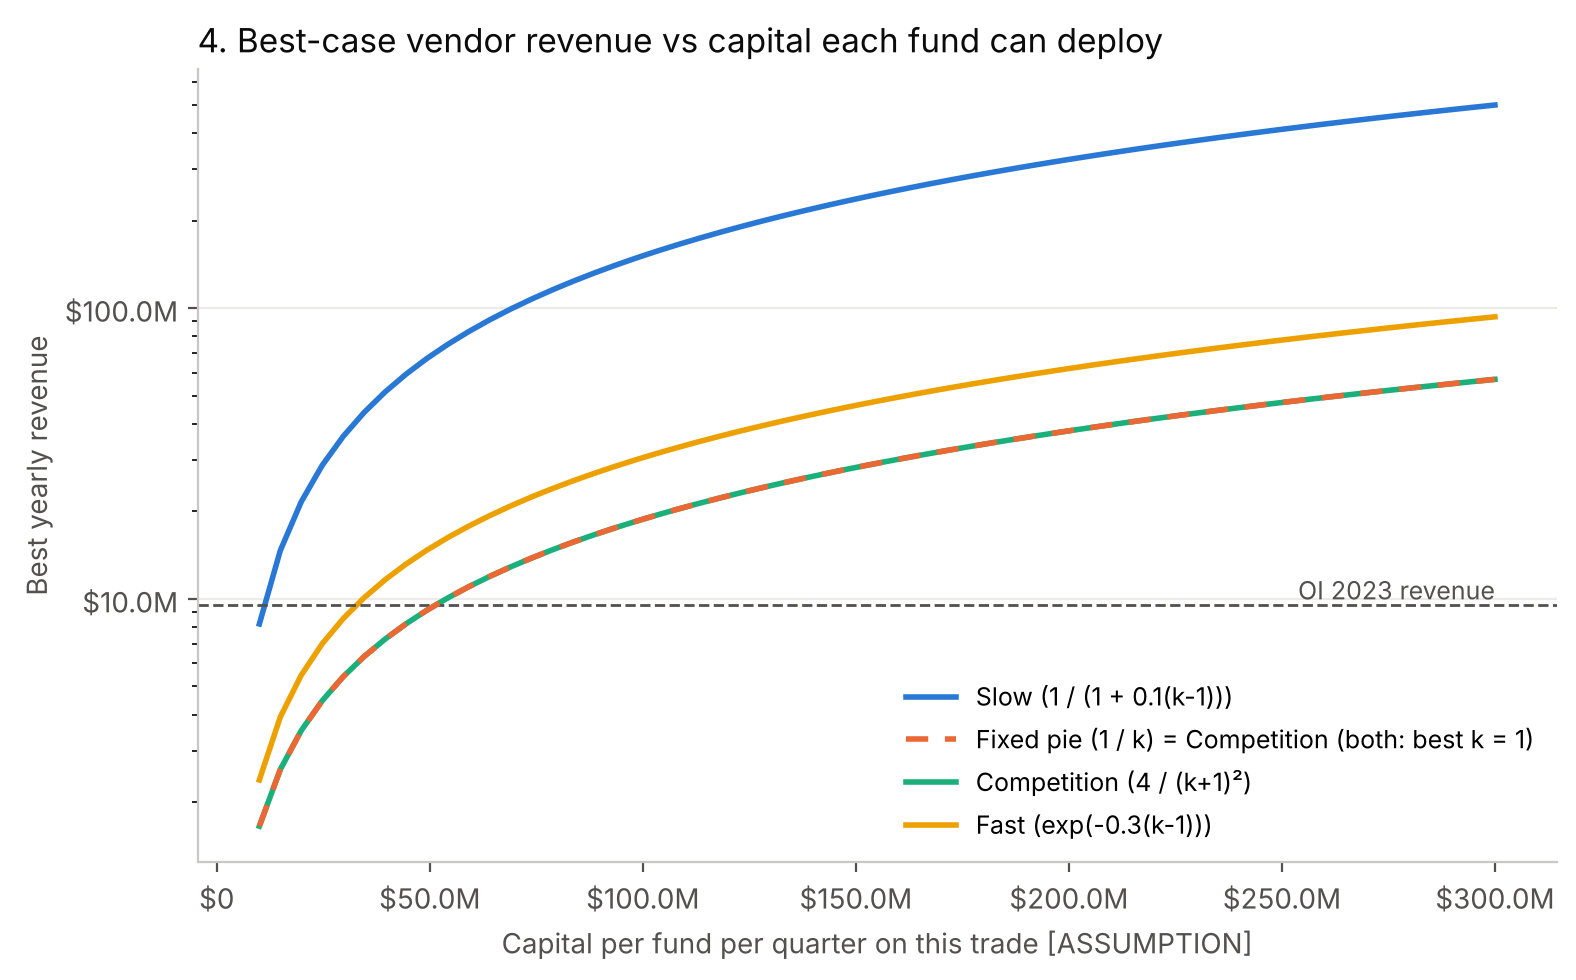

In [6]:
# How big is the whole prize? Best possible vendor revenue as fund capital varies.
caps = np.linspace(10e6, 300e6, 60)
fig, ax = plt.subplots(figsize=(8, 5))
for (name, d), c in zip(DECAY.items(), COLORS):
    best = [vendor_revenue(k, d, capital=cp).max() for cp in caps]
    pie = name.startswith("Fixed")
    ax.plot(caps, best, color=c, lw=2, ls=(0, (4, 3)) if pie else "-", zorder=3 if pie else 2,
            label=name + (" = Competition (both: best k = 1)" if pie else ""))
style(ax, "4. Best-case vendor revenue vs capital each fund can deploy", "Best yearly revenue")
ax.set_xlabel("Capital per fund per quarter on this trade [ASSUMPTION]", color="#52514e")
ax.set_yscale("log"); ax.xaxis.set_major_formatter(money); ax.yaxis.set_major_formatter(money)
ax.axhline(OI_REVENUE_2023, color="#52514e", ls="--", lw=1)
ax.text(caps[-1], OI_REVENUE_2023, "OI 2023 revenue", ha="right", va="bottom", color="#52514e", fontsize=9)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig("fig2_market_size.png", dpi=180); plt.show()


### Reading figure 4
(Log scale.) Under the three fast curves, the vendor's best revenue is about what **one** exclusive fund earns. It grows only if each fund can put more money into the trade. Even at a very generous $300M per fund per quarter, with the vendor taking *every* dollar of profit, the ceiling is about $57–93M a year. Only the slow curve supports a large business, and the calibration check above rules that curve out. One signal is a small prize next to $130M of venture capital.

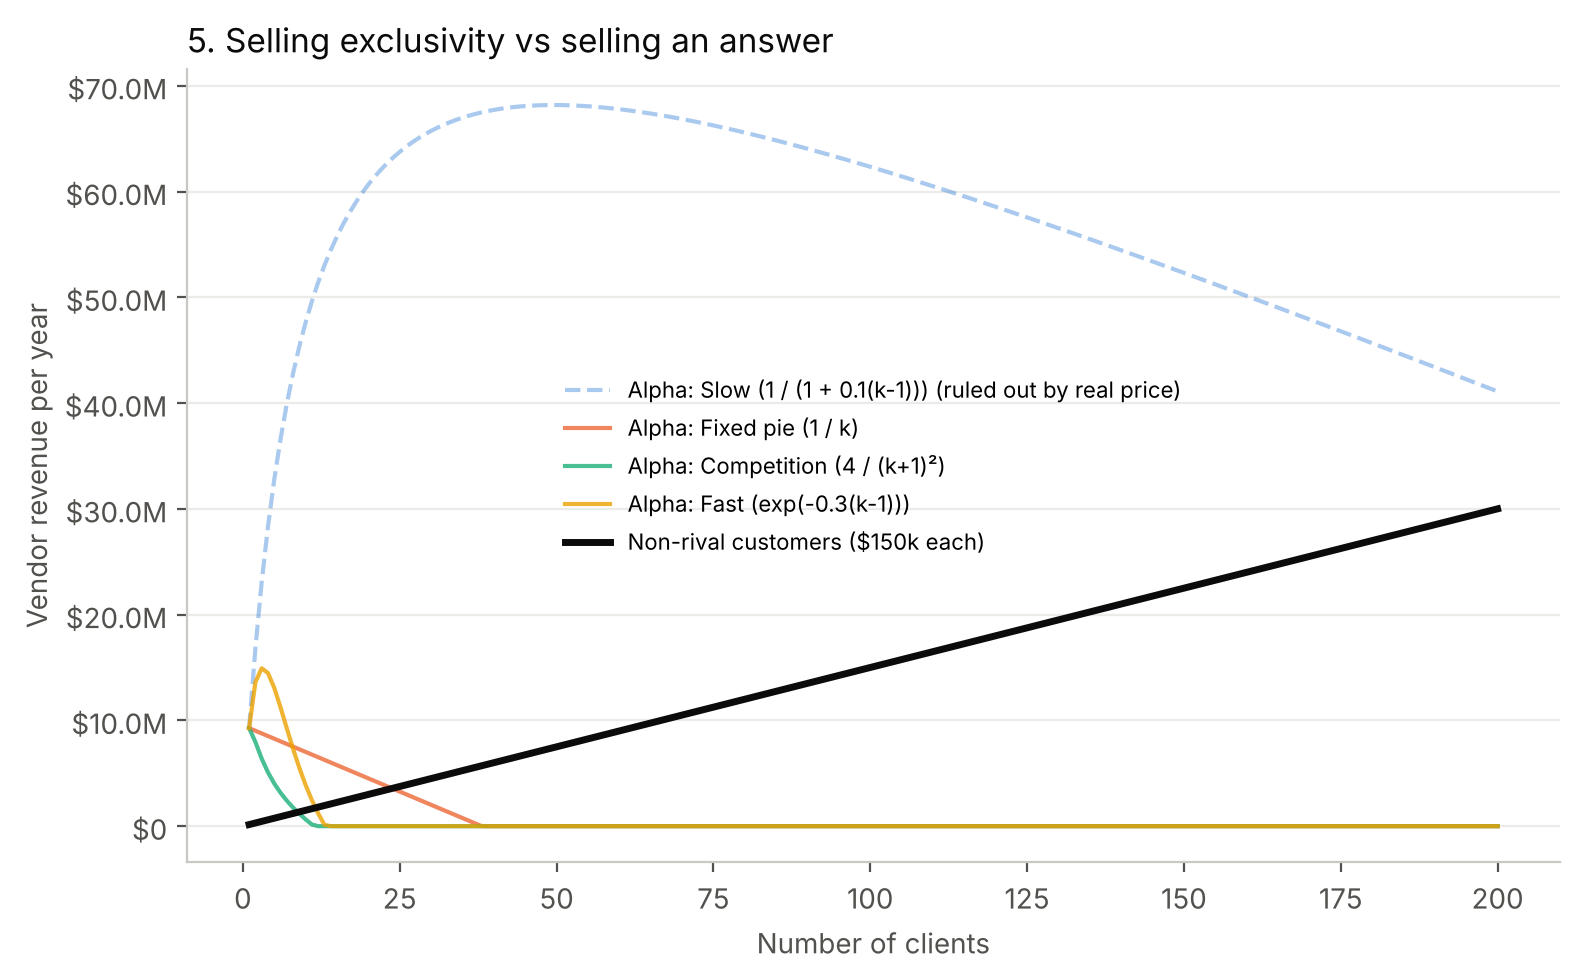

In [7]:
# New entrant: customers who do NOT lose value when others have the data
# (construction / land-use monitoring, deforestation compliance under the EUDR, insurers).
VALUE_NONRIVAL = 150e3   # [ASSUMPTION] yearly value per compliance/monitoring client
n = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(8, 5))
for (name, d), c in zip(DECAY.items(), COLORS):
    kk = np.arange(1, 201)
    slow = name.startswith("Slow")
    ax.plot(n, vendor_revenue(kk, d), color=c, lw=1.5, ls="--" if slow else "-", alpha=0.4 if slow else 0.8,
            label=f"Alpha: {name}" + (" (ruled out by real price)" if slow else ""))
ax.plot(n, n * VALUE_NONRIVAL, color="#0b0b0b", lw=2.5, label="Non-rival customers ($150k each)")
style(ax, "5. Selling exclusivity vs selling an answer", "Vendor revenue per year")
ax.set_xlabel("Number of clients", color="#52514e")
ax.yaxis.set_major_formatter(money); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("fig3_new_entrant.png", dpi=180); plt.show()


### Reading figure 5
Under the curves that fit the real price, revenue from an alpha signal peaks after a handful of clients and then falls, because each new client erodes what the others pay. Revenue from customers who want an *answer*, not an edge, keeps growing with every client, and there are far more such clients than quant funds. That is the shift our note recommends for a new entrant.

In [8]:
# Play with the assumptions (works in Colab / Jupyter)
from ipywidgets import interact, FloatSlider
@interact(capital_M=FloatSlider(value=50, min=5, max=300, step=5, description="Capital $M"),
          processing_k=FloatSlider(value=250, min=0, max=1000, step=25, description="Processing $k"))
def explore(capital_M, processing_k):
    for name, d in DECAY.items():
        r = vendor_revenue(k, d, capital=capital_M*1e6, processing=processing_k*1e3)
        i = int(np.argmax(r))
        print(f"{name:30s} best k={k[i]:3d}  price={fmt(price(k[i], d, capital_M*1e6, processing_k*1e3)):>8s}  revenue={fmt(r[i]):>8s}")


interactive(children=(FloatSlider(value=50.0, description='Capital $M', max=300.0, min=5.0, step=5.0), FloatSl…

## What is real and what is assumed
| Input | Value | Source |
|---|---|---|
| Edge when exclusive | 4.76% per 3-day window | **Real**: Katona et al. (2025), Table 3 |
| Earnings events per year | 4 | **Real**: quarterly reporting |
| Price of data | "hundreds of thousands" $/yr | **Real**: Katona et al. (2025), p. 556 |
| Funding / 2023 revenue | $130M / $9.5M | **Real**: Poulson (2023) |
| Capital per fund per trade | $50M (varied $10–300M) | **Assumption** |
| Fund processing cost | $250k/yr | **Assumption** |
| How fast the edge shrinks | four curves | **Assumption** (the key unknown) |
| Vendor captures all fund profit | | **Assumption**: makes revenue an *upper bound* |
| Non-rival client value | $150k/yr | **Assumption** |

**Limits:** the 4.76% is measured from 2011–2017 data, when few funds had it, so it already reflects some sharing. The model ignores trading costs and price impact beyond the decay curve. It covers a single product.